# 02 — Interaction & Robustness

So cùng các tổ hợp quan sát là segment comparison, không phải kiểm soát mọi confounder. Cell nhỏ/không overlap được giữ trong bảng nhưng không dùng kết luận chính; ngưỡng n ≥ 30 cho mỗi nhóm là sàng lọc mô tả. Không kiểm định significance; không suy luận về quần thể hay nhân quả.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/Social_Media_Content_Performance_Dataset.xlsx").exists())
step2 = next(p for p in root.iterdir() if p.is_dir() and p.name.startswith("2."))
out = next(p for p in root.iterdir() if p.is_dir() and p.name.startswith("3."))
tables = out / "artifacts/tables"
figures = out / "artifacts/figures"
for path in [tables, figures]:
    path.mkdir(parents=True, exist_ok=True)
source = pd.read_csv(step2 / "artifacts/analysis_ready.csv",
                     parse_dates=["Post_Date", "Post_Published_At"])
assert source.Source_Row.is_unique
for col in ["Engagement_Rate", "Views", "Impressions", "Engagement"]:
    source.loc[source["Invalid_"+col], col] = np.nan
# No new cleaning, imputation, recoding or deduplication.
# Main analysis uses full publication-month cohorts; partial month is sensitivity only.
data = source.loc[~source.Partial_Month].copy()
data["Group"] = np.where(data.Content_Category.eq("Entertainment"), "Entertainment", "Rest")
N_E = int(data.Group.eq("Entertainment").sum())
N_R = len(data)-N_E
THRESHOLD = 30  # per group per cell; descriptive screening, not a power calculation

def save(table, name):
    table.to_csv(tables / (name+".csv"), index=True)

def pairs(frame, columns, threshold=THRESHOLD):
    groups = {label: g for label, g in frame.groupby(columns, dropna=False)}
    rows = []
    for label, group in groups.items():
        labels = label if isinstance(label, tuple) else (label,)
        row = dict(zip(columns, labels))
        for short, mask in [("E", group.Content_Category.eq("Entertainment")),
                            ("R", ~group.Content_Category.eq("Entertainment"))]:
            g = group.loc[mask]
            row.update({"n_"+short: len(g), "er_n_"+short: g.Engagement_Rate.count(),
                "mean_"+short: g.Engagement_Rate.mean()*100,
                "median_"+short: g.Engagement_Rate.median()*100 if len(g) else np.nan,
                "views_"+short: g.Views.sum(min_count=1),
                "impressions_"+short: g.Impressions.sum(min_count=1),
                "engagement_"+short: g.Engagement.sum(min_count=1)})
        row['gap_pp'] = row['mean_R']-row['mean_E']
        row['median_gap_pp'] = row['median_R']-row['median_E']
        row['eligible'] = min(row['er_n_E'], row['er_n_R']) >= threshold
        rows.append(row)
    result = pd.DataFrame(rows).set_index(columns)
    result['mix_E_pct'] = result.n_E / frame.Content_Category.eq('Entertainment').sum()*100
    result['mix_R_pct'] = result.n_R / (~frame.Content_Category.eq('Entertainment')).sum()*100
    return result

def decomposition(table, driver):
    # Common support with adequate sample in BOTH groups; excluded cells retained in tables.
    t = table.loc[table.eligible].copy()
    if t.empty:
        return {"driver": driver, "eligible_cells": 0}
    pE, pR = t.n_E/t.n_E.sum(), t.n_R/t.n_R.sum()
    mE, mR = t.mean_E, t.mean_R
    composition = ((pR-pE)*(mR+mE)/2).sum()
    within = ((pR+pE)/2*(mR-mE)).sum()
    subset_gap = (pR*mR).sum()-(pE*mE).sum()
    assert np.isclose(composition+within, subset_gap)
    return {"driver": driver, "eligible_cells": len(t),
        "coverage_E_pct": t.n_E.sum()/N_E*100, "coverage_R_pct": t.n_R.sum()/N_R*100,
        "supported_subset_gap_pp": subset_gap, "composition_pp": composition,
        "within_segment_pp": within,
        "rest_standardized_to_E_pct": (pE*mR).sum(), "E_supported_mean_pct": (pE*mE).sum(),
        "E_mix_standardized_gap_pp": (pE*(mR-mE)).sum(),
        "min_cell_gap_pp": t.gap_pp.min(), "max_cell_gap_pp": t.gap_pp.max(),
        "cells_E_at_or_above_rest": int((t.gap_pp<=0).sum())}

def category_table(columns):
    t = data.groupby(columns+["Content_Category"]).agg(
        records=("Source_Row", "size"), er_records=("Engagement_Rate", "count"),
        mean_source_er=("Engagement_Rate", "mean"), median_source_er=("Engagement_Rate", "median"),
        views=("Views", "sum"), impressions=("Impressions", "sum"), engagement=("Engagement", "sum"))
    t['mean_source_er_pct'] = t.pop('mean_source_er')*100
    t['median_source_er_pct'] = t.pop('median_source_er')*100
    t['small_sample'] = t.er_records < THRESHOLD
    return t

baseline = category_table([])
display(baseline.round(3))
save(baseline, "category_baseline_full_months")
print("Full-month records E / Rest:", N_E, N_R)
print("Main metric: source ER mean/median, not Engagement/Views computed from totals.")


,records,er_records,views,impressions,engagement,mean_source_er_pct,median_source_er_pct,small_sample
Content_Category,,,,,,,,
Customer Story,733,733,3.660037e+08,4.384198e+08,72560404.0,19.868,19.798,False
Educational,2022,2022,1.192770e+09,1.428779e+09,237228391.0,19.884,19.740,False
Entertainment,876,876,1.096326e+09,1.317153e+09,81814900.0,7.511,7.509,False
Event / Webinar,576,576,2.174810e+08,2.611021e+08,30543050.0,13.944,14.080,False
Product Promotion,1383,1383,1.925420e+09,2.311199e+09,223016263.0,11.594,11.600,False


Full-month records E / Rest: 876 4714
Main metric: source ER mean/median, not Engagement/Views computed from totals.


In [2]:
interaction_effects = []
interactions = {}
for cols in [["Platform", "Post_Type"], ["Platform", "Content_Type"],
             ["Region", "Post_Type"], ["Post_Type", "Content_Type"],
             ["Platform", "Post_Hour"]]:
    name = "_x_".join(cols)
    t = pairs(data, cols)
    interactions[name] = t
    save(t, "interaction_"+name.lower())
    interaction_effects.append(decomposition(t, name))
interaction_effects = pd.DataFrame(interaction_effects).set_index('driver')
display(interaction_effects.round(3))
save(interaction_effects, 'interaction_effect_summary')
for cols in [["Platform"], ["Post_Type"], ["Region"], ["Content_Type"],
             ["Month"], ["Weekday"], ["Post_Hour"], ["Platform", "Post_Type"]]:
    table = category_table(cols)
    save(table, 'interaction_categories_'+'_x_'.join(cols).lower())
    if len(cols)==1 and cols[0] in ['Platform','Post_Type','Region','Content_Type']:
        print(cols[0], 'x category (mean source ER %)')
        display(table.mean_source_er_pct.unstack('Content_Category').round(3))
print('Platform x Post_Type eligible gap:')
display(interactions['Platform_x_Post_Type'].loc[lambda t: t.eligible,
    ['n_E','n_R','mean_E','mean_R','gap_pp','median_gap_pp','views_E','views_R']].round(3))


,eligible_cells,coverage_E_pct,coverage_R_pct,supported_subset_gap_pp,composition_pp,within_segment_pp,rest_standardized_to_E_pct,E_supported_mean_pct,E_mix_standardized_gap_pp,min_cell_gap_pp,max_cell_gap_pp,cells_E_at_or_above_rest
driver,,,,,,,,,,,,
Platform_x_Post_Type,8,90.753,66.059,9.272,0.323,8.949,16.153,7.499,8.654,3.998,10.033,0
Platform_x_Content_Type,8,91.781,90.984,9.169,-0.017,9.186,16.727,7.528,9.199,8.453,10.473,0
Region_x_Post_Type,8,77.397,48.091,9.040,0.011,9.028,16.485,7.466,9.019,8.585,9.367,0
Post_Type_x_Content_Type,4,91.096,71.977,9.528,0.199,9.329,16.716,7.519,9.197,8.921,10.584,0
Platform_x_Post_Hour,4,15.183,10.289,9.364,-0.036,9.400,17.132,7.642,9.489,8.831,10.284,0


Content_Category,Customer Story,Educational,Entertainment,Event / Webinar,Product Promotion
Platform,,,,,
Facebook,19.251,20.273,7.494,14.851,11.645
Instagram,19.809,19.978,7.395,13.994,11.497
LinkedIn,19.851,19.778,7.570,13.988,11.873
TikTok,20.443,20.012,7.342,14.062,11.556
X.com,19.968,19.820,7.482,14.051,11.533
YouTube,19.689,19.730,7.707,13.569,11.648


Content_Category,Customer Story,Educational,Entertainment,Event / Webinar,Product Promotion
Post_Type,,,,,
Article,20.013,19.813,7.322,NaN,11.144
Carousel,20.240,19.260,7.424,NaN,12.918
Image,19.627,19.986,7.785,14.152,11.536
Live Stream,20.134,19.934,NaN,13.910,11.565
PDF,NaN,20.645,9.463,14.390,17.203
Text,19.569,19.960,7.775,13.657,11.219
Video,20.005,19.816,7.466,15.680,11.601


Content_Category,Customer Story,Educational,Entertainment,Event / Webinar,Product Promotion
Region,,,,,
Australia,20.047,19.941,7.525,13.863,11.845
Brazil,19.936,20.185,7.492,14.316,11.668
Canada,19.625,19.671,7.592,13.914,11.479
Germany,19.737,19.790,7.339,13.792,11.600
India,19.948,19.998,7.519,14.288,11.454
Japan,19.459,19.855,7.471,14.128,11.507
UK,20.059,19.952,7.457,13.686,11.428
USA,19.941,19.696,7.703,13.636,11.747


Content_Category,Customer Story,Educational,Entertainment,Event / Webinar,Product Promotion
Content_Type,,,,,
Organic,19.848,19.888,7.538,13.944,11.605
Sponsored,19.938,19.862,7.410,NaN,11.541


n_E  n_R  mean_E  mean_R  gap_pp  median_gap_pp      views_E      views_R
Platform  Post_Type                                                                           
Instagram Video      103  285   7.401  14.618   7.217          6.438  210290736.0  582106458.0
LinkedIn  Article     39  167   7.322  16.906   9.584         10.259   37966222.0  151300592.0
          Video       66   33   7.577  11.575   3.998          4.398   32003432.0   15501623.0
TikTok    Video      193  803   7.342  17.375  10.033         10.511  245970633.0  746281280.0
X.com     Image       53  435   7.801  17.476   9.674          9.661   26046977.0  127957002.0
          Text        37  313   7.640  17.644  10.003         10.000   19508288.0   94960097.0
          Video       87  272   7.221  14.090   6.869          5.849  176164028.0  550431069.0
YouTube   Video      217  806   7.707  17.303   9.595          9.853  261015899.0  739295836.0

Platform x category (mean source ER %)
Post_Type x category (mean source ER %)
Region x category (mean source ER %)
Content_Type x category (mean source ER %)
Platform x Post_Type eligible gap:


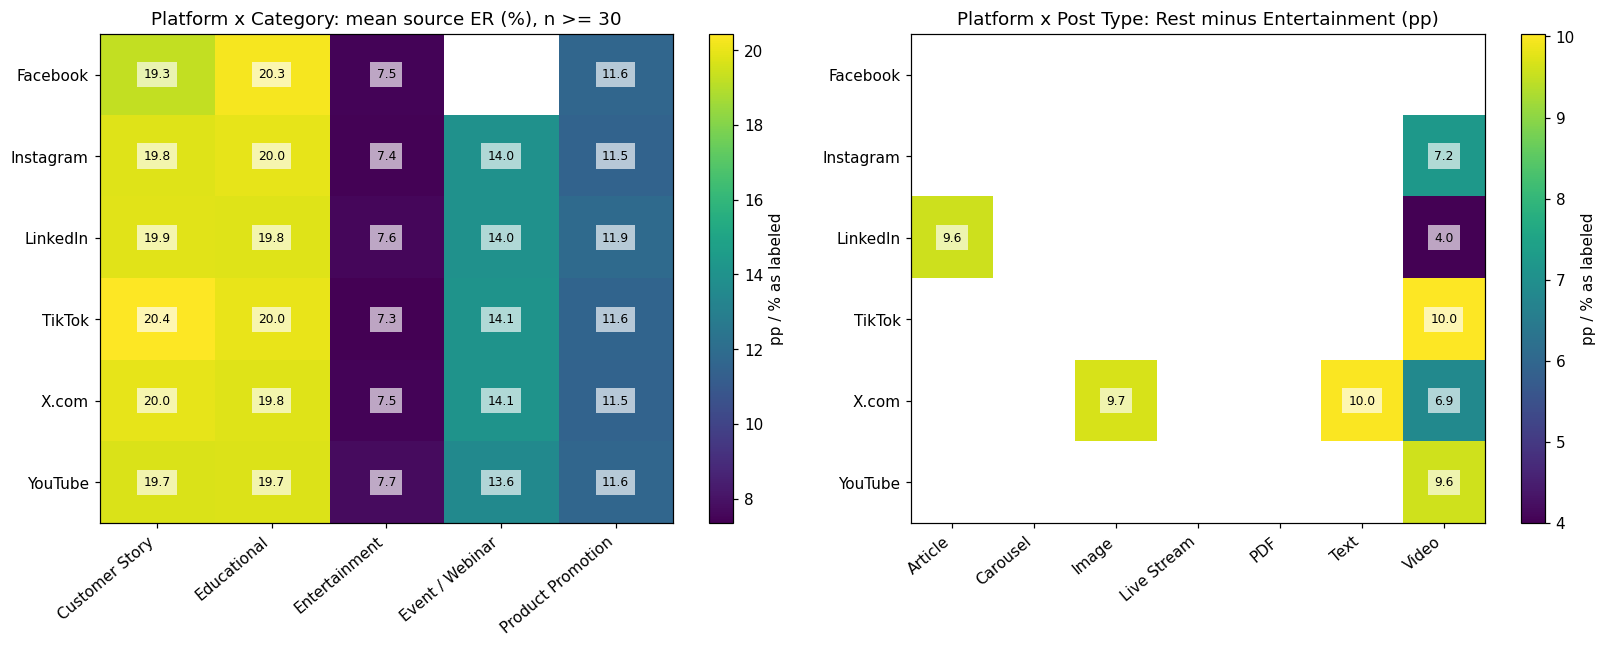

In [3]:
def heatmap(ax, values, title, cmap='viridis'):
    arr = values.to_numpy(dtype=float)
    masked = np.ma.masked_invalid(arr)
    im = ax.imshow(masked, aspect='auto', cmap=cmap)
    ax.set_xticks(range(len(values.columns)), values.columns, rotation=40, ha='right')
    ax.set_yticks(range(len(values)), values.index)
    for i in range(len(values)):
        for j in range(len(values.columns)):
            if np.isfinite(arr[i,j]):
                ax.text(j,i,f'{arr[i,j]:.1f}',ha='center',va='center',fontsize=8,
                        bbox={'facecolor':'white','alpha':.65,'edgecolor':'none'})
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label='pp / % as labeled')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
c = category_table(['Platform'])
heatmap(axes[0], c.mean_source_er_pct.where(~c.small_sample).unstack('Content_Category'),
        'Platform x Category: mean source ER (%), n >= 30')
t = interactions['Platform_x_Post_Type']
heatmap(axes[1], t.gap_pp.where(t.eligible).unstack('Post_Type'),
        'Platform x Post Type: Rest minus Entertainment (pp)')
fig.tight_layout()
fig.savefig(figures / 'interaction_heatmaps.png', dpi=150, bbox_inches='tight')


## Robustness

Mean/median so toàn mẫu và trong cell. Kiểm tra tháng/platform/region, ngưỡng n=10/30/50 và leave-one-group-out. Winsor 1% áp dụng cùng ngưỡng pooled ER cho hai nhóm, chỉ là sensitivity, không cập nhật dataset. Loại top 1% Views chỉ là phép kiểm tra xem record exposure lớn có làm thay đổi kết quả, không khẳng định outlier là lỗi.

Mã bài lặp: trọng số từng record bằng 1/số record Post_ID. Giữ category của từng record; một số ID có nhiều category. Đây không phải deduplication hoặc xác nhận grain. Các sensitivity không phải tập kết quả độc lập để tính significance.

Trong dòng trọng số Post_ID, chỉ mean được weighted; cột median vẫn là median record không trọng số để đối chiếu. Các ô trống trên heatmap là thiếu common support hoặc n < 30, không phải ER bằng 0.


,n_E,n_R,mean_E_pct,mean_R_pct,mean_gap_pp,median_gap_pp
check,,,,,,
Full months,876,4714,7.5111,16.7236,9.2124,9.1422
Including partial May,877,4723,7.5119,16.7268,9.2149,9.1413
Each Post_ID total weight=1,876,4714,7.5137,16.7301,9.2164,9.1422
Pooled ER winsor 1%/99% (sensitivity only),876,4714,7.5265,16.7218,9.1953,9.1422
Exclude Views above pooled p99 (sensitivity only),857,4677,7.5055,16.7387,9.2332,9.1577


,n_E,n_R,mean_E_pct,mean_R_pct,mean_gap_pp,median_gap_pp
check,,,,,,
Exclude Platform: Facebook,830,4461,7.512,16.725,9.212,9.132
Exclude Platform: Instagram,771,3822,7.527,16.697,9.171,9.129
Exclude Platform: LinkedIn,738,4330,7.500,16.723,9.223,9.120
Exclude Platform: TikTok,683,3651,7.559,16.702,9.143,9.056
Exclude Platform: X.com,699,3694,7.518,16.751,9.233,9.165
Exclude Platform: YouTube,659,3612,7.447,16.745,9.299,9.275
Exclude Region: Australia,768,4143,7.509,16.690,9.181,9.119
Exclude Region: Brazil,770,4105,7.514,16.713,9.200,9.120
Exclude Region: Canada,758,4098,7.498,16.712,9.214,9.184


,driver,eligible_cells,coverage_E_pct,coverage_R_pct,supported_subset_gap_pp,composition_pp,within_segment_pp,rest_standardized_to_E_pct,E_supported_mean_pct,E_mix_standardized_gap_pp,min_cell_gap_pp,max_cell_gap_pp,cells_E_at_or_above_rest,minimum_n_each
0,Platform,6,100.000,100.000,9.212,-0.005,9.217,16.717,7.511,9.206,8.946,9.456,0,10
1,Post_Type,5,99.886,80.102,9.638,0.202,9.436,16.803,7.509,9.294,9.040,10.950,0,10
2,Region,8,100.000,100.000,9.212,0.008,9.205,16.715,7.511,9.203,8.895,9.442,0,10
3,Month,16,100.000,100.000,9.212,-0.006,9.219,16.726,7.511,9.215,8.265,9.827,0,10
4,Platform_x_Post_Type,12,97.831,70.789,9.300,0.287,9.013,16.246,7.498,8.748,3.998,11.359,0,10
5,Platform,6,100.000,100.000,9.212,-0.005,9.217,16.717,7.511,9.206,8.946,9.456,0,30
6,Post_Type,4,97.831,79.402,9.626,0.213,9.413,16.770,7.511,9.260,9.040,10.798,0,30
7,Region,8,100.000,100.000,9.212,0.008,9.205,16.715,7.511,9.203,8.895,9.442,0,30
8,Month,16,100.000,100.000,9.212,-0.006,9.219,16.726,7.511,9.215,8.265,9.827,0,30
9,Platform_x_Post_Type,8,90.753,66.059,9.272,0.323,8.949,16.153,7.499,8.654,3.998,10.033,0,30


Winsor thresholds: 0.054116116676225325 0.2480201749183569 ; changed records: 112
Top exposure records excluded: 56


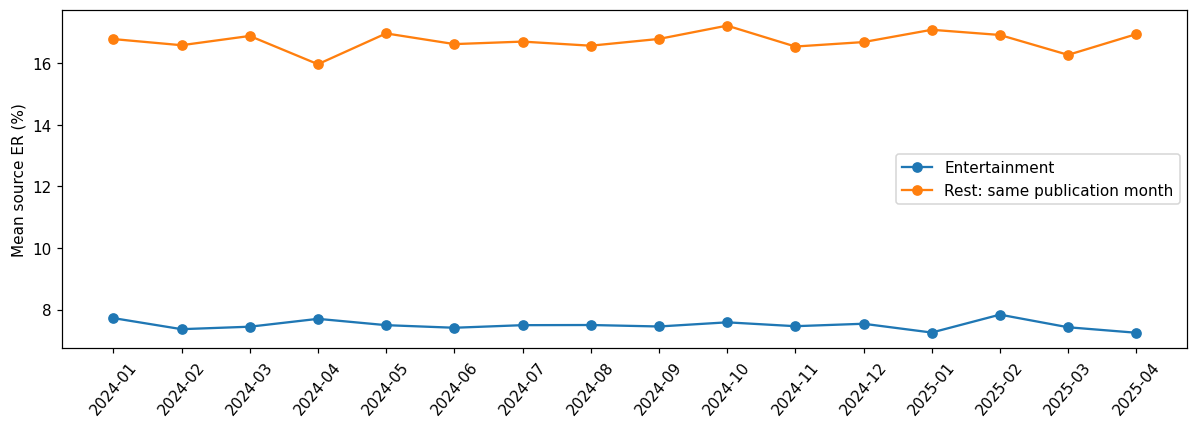

In [4]:
def gap_summary(frame, label, er_col='Engagement_Rate', weights=None):
    mask = frame.Content_Category.eq('Entertainment')
    a,b = frame.loc[mask], frame.loc[~mask]
    ma,mb = a[er_col].mean()*100,b[er_col].mean()*100
    if weights is not None:
        ma=np.average(a[er_col],weights=weights.loc[mask])*100
        mb=np.average(b[er_col],weights=weights.loc[~mask])*100
    return {'check':label,'n_E':len(a),'n_R':len(b),'mean_E_pct':ma,'mean_R_pct':mb,
            'mean_gap_pp':mb-ma,'median_gap_pp':(b[er_col].median()-a[er_col].median())*100}

robust = [gap_summary(data,'Full months'), gap_summary(source,'Including partial May')]
weights = 1/data.groupby('Post_ID').Post_ID.transform('size')
robust.append(gap_summary(data,'Each Post_ID total weight=1',weights=weights))
lo,hi = data.Engagement_Rate.quantile([.01,.99])
winsor = data.copy()
winsor['ER_sensitivity'] = winsor.Engagement_Rate.clip(lo,hi)
robust.append(gap_summary(winsor,'Pooled ER winsor 1%/99% (sensitivity only)','ER_sensitivity'))
exposure = data.loc[data.Views <= data.Views.quantile(.99)]
robust.append(gap_summary(exposure,'Exclude Views above pooled p99 (sensitivity only)'))
robust = pd.DataFrame(robust).set_index('check')
display(robust.round(4)); save(robust,'robustness_overall')
print('Winsor thresholds:',lo,hi,'; changed records:',int(winsor.ER_sensitivity.ne(winsor.Engagement_Rate).sum()))
print('Top exposure records excluded:',len(data)-len(exposure))
leave = []
for col in ['Platform','Region']:
    for value in sorted(data[col].unique()):
        leave.append(gap_summary(data.loc[data[col].ne(value)], 'Exclude '+col+': '+value))
leave = pd.DataFrame(leave).set_index('check')
save(leave,'leave_one_segment_out');display(leave.round(3))
thresholds = []
for threshold in [10,30,50]:
    for cols in [['Platform'],['Post_Type'],['Region'],['Month'],['Platform','Post_Type']]:
        row = decomposition(pairs(data,cols,threshold),'_x_'.join(cols))
        row['minimum_n_each'] = threshold
        thresholds.append(row)
thresholds = pd.DataFrame(thresholds)
save(thresholds,'sample_threshold_sensitivity');display(thresholds.round(3))
by_month = pairs(data,['Month'])
save(by_month,'robustness_monthly')
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(by_month.index,by_month.mean_E,marker='o',label='Entertainment')
ax.plot(by_month.index,by_month.mean_R,marker='o',label='Rest: same publication month')
ax.set_ylabel('Mean source ER (%)'); ax.tick_params(axis='x',rotation=50);ax.legend()
fig.tight_layout();fig.savefig(figures/'monthly_gap_robustness.png',dpi=150,bbox_inches='tight')


## Secondary scope: Product Promotion

Chỉ kiểm tra xem secondary gap có còn trong segment cùng platform/post type/region. Không đổi trọng tâm và không xây dựng thêm mô hình giải thích.


In [5]:
secondary = []
for col in ['Platform','Post_Type','Region']:
    for label,g in data.groupby(col):
        a=g.loc[g.Content_Category.eq('Product Promotion')]
        b=g.loc[~g.Content_Category.eq('Product Promotion')]
        secondary.append({'driver':col,'segment':label,'n_product':len(a),'n_rest':len(b),
                          'product_er_pct':a.Engagement_Rate.mean()*100,
                          'rest_er_pct':b.Engagement_Rate.mean()*100,
                          'gap_pp':(b.Engagement_Rate.mean()-a.Engagement_Rate.mean())*100,
                          'eligible':min(len(a),len(b))>=THRESHOLD})
secondary = pd.DataFrame(secondary)
save(secondary,'secondary_product_promotion')
display(secondary.round(3))
print('Primary E gap positive in all eligible Platform/Region/Month cells:')
for col in ['Platform','Region','Month']:
    t=pairs(data,[col]); t=t.loc[t.eligible]
    print(col,len(t),bool(t.gap_pp.gt(0).all()))


,driver,segment,n_product,n_rest,product_er_pct,rest_er_pct,gap_pp,eligible
0,Platform,Facebook,82,217,11.645,16.667,5.022,True
1,Platform,Instagram,239,758,11.497,17.211,5.714,True
2,Platform,LinkedIn,120,402,11.873,15.039,3.166,True
3,Platform,TikTok,324,932,11.556,16.662,5.106,True
4,Platform,X.com,306,891,11.533,16.557,5.024,True
5,Platform,YouTube,312,1007,11.648,16.276,4.628,True
6,Post_Type,Article,57,149,11.144,16.601,5.458,True
7,Post_Type,Carousel,6,45,12.918,14.721,1.804,False
8,Post_Type,Image,95,898,11.536,18.510,6.974,True
9,Post_Type,Live Stream,229,694,11.565,16.090,4.525,True


Primary E gap positive in all eligible Platform/Region/Month cells:
Platform 6 True
Region 8 True
Month 16 True
